# Simulation 3

## imports:

In [29]:
from rocketpy import Environment , Rocket , SolidMotor , Flight
from rocketpy.simulation import FlightDataExporter
import numpy as np
import matplotlib.pyplot as plt

## Environment Definition:


Gravity Details

Acceleration of gravity at surface level:    9.7890 m/s²
Acceleration of gravity at  80.000 km (ASL): 9.7890 m/s²


Launch Site Details

Launch Site Latitude: 18.25569°
Launch Site Longitude: -67.14847°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 61158.85 W    2023456.95 N
Launch Site UTM zone: 20Q
Launch Site Surface Elevation: 8.8 m


Atmospheric Model Details

Atmospheric Model Type: custom_atmosphere
custom_atmosphere Maximum Height: 80.000 km

Surface Atmospheric Conditions

Surface Wind Speed: 5.00 m/s
Surface Wind Direction: 270.00°
Surface Wind Heading: 90.00°
Surface Pressure: 1012.22 hPa
Surface Temperature: 288.09 K
Surface Air Density: 1.224 kg/m³
Surface Speed of Sound: 340.26 m/s


Earth Model Details

Earth Radius at Launch site: 6376.05 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034


Atmospheric Model Plots



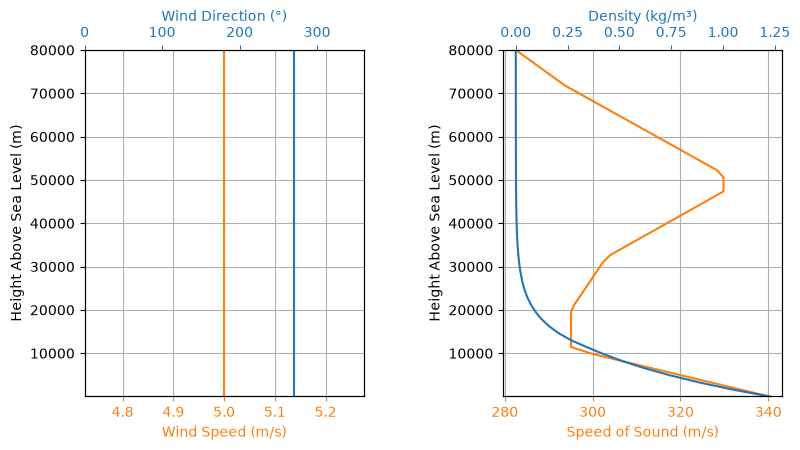

In [30]:
# Aeropuerto Eugenio Maria de Hostos , mayaguez
env = Environment(
    gravity= 9.789,
    latitude = 18.255686 ,
    longitude=-67.148472,
    elevation= 8.75 ,
    timezone= "America/Puerto_Rico"  
)
# # Perfil de ráfaga: (altitud en metros, velocidad en m/s)
# #rafaga_viento = [
#     (0, 0),       # Suelo
#     (400, 0),     # Hasta los 400m
#     (500, 15),    # A los 500m 
#     (600, 0),     # A los 600m
#     (5000, 0)     # El resto del vuelo
# #]


env.set_atmospheric_model(type="custom_atmosphere",pressure=None,temperature=None,wind_u=5.00,wind_v=0)
env.info()

## Motor Definition:

Nozzle Details
Nozzle Radius: 0.033 m
Nozzle Throat Radius: 0.011 m

Grain Details
Number of Grains: 5
Grain Spacing: 0.005 m
Grain Density: 1815 kg/m3
Grain Outer Radius: 0.033 m
Grain Inner Radius: 0.015 m
Grain Height: 0.12 m
Grain Volume: 0.000 m3
Grain Mass: 0.591 kg

Motor Details
Total Burning Time: 3.9 s
Total Propellant Mass: 2.956 kg
Structural Mass Ratio: 0.380
Average Propellant Exhaust Velocity: 2038.745 m/s
Average Thrust: 1545.218 N
Maximum Thrust: 2200.0 N at 0.15 s after ignition.
Total Impulse: 6026.350 Ns



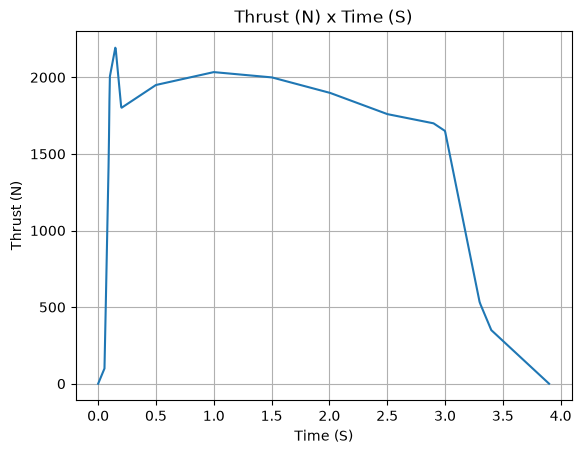

In [31]:
# Defining the solid motor that will be used
Pro75M1670 = SolidMotor(
    thrust_source="../data/motors/cesaroni/Cesaroni_M1670.eng",
    dry_mass=1.815,
    dry_inertia=(0.125, 0.125, 0.002),
    nozzle_radius=33 / 1000,
    grain_number=5,
    grain_density=1815,
    grain_outer_radius=33 / 1000,
    grain_initial_inner_radius=15 / 1000,
    grain_initial_height=120 / 1000,
    grain_separation=5 / 1000,
    grains_center_of_mass_position=0.397,
    center_of_dry_mass_position=0.317,
    nozzle_position=0,
    burn_time=3.9,
    throat_radius=11 / 1000,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)
Pro75M1670.info()

## Rocket 1 Definition:

In [32]:
# Defining r1 Rocket
r1 = Rocket(
    radius= 127/2000,
    mass= 14.426,
    inertia=(6.321, 6.321, 0.034), # same inertia as the documentation example
    power_off_drag="../data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag="../data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose"

)
r1.add_motor(Pro75M1670,position=-1.255)
ail_buttons = r1.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

nose_cone = r1.add_nose(
    length=0.55829, kind="von karman", position=1.278
)

fin_set = r1.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0.5,
    airfoil=("../data/airfoils/NACA0012-radians.txt","radians"),
)

tail = r1.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

main = r1.add_parachute(
    name="main",
    cd_s=10.0,
    trigger=800,      # ejection altitude in meters
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

drogue = r1.add_parachute(
    name="drogue",
    cd_s=1.0,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

r1.info()


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 7.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 7.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient De

## Rocket 2 Definition:

In [33]:
# Defining r2 Rocket
r2 = Rocket(
    radius= 127/2000,
    mass= 14.426,
    inertia=(9.321,9.321, 0.034), # new inertia incremented 3.000 kg*m^2 the pitch and yaw
    power_off_drag="../data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag="../data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose"
)

r2.add_motor(Pro75M1670,position=-1.255)
ail_buttons = r2.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

nose_cone = r2.add_nose(
    length=0.55829, kind="von karman", position=1.278
)

fin_set = r2.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0.5,
    airfoil=("../data/airfoils/NACA0012-radians.txt","radians"),
)

tail = r2.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

main = r2.add_parachute(
    name="main",
    cd_s=10.0,
    trigger=800,      # ejection altitude in meters
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

drogue = r2.add_parachute(
    name="drogue",
    cd_s=1.0,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

r2.info()


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 10.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 10.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient 

## Rocket 3 Definition:

In [ ]:
# defining r3 Rocket
r3 = Rocket(radius=127/2000,
    mass=14.426,
    inertia=(8.321,8.321, 0.034), #incremented yaw and pitch by 2.00 kg*m^2
    power_off_drag="../data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag="../data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose"
)

r3.add_motor(Pro75M1670,position=-1.255)
ail_buttons = r3.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

nose_cone = r3.add_nose(
    length=0.55829, kind="von karman", position=1.278
)

fin_set = r3.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0.5,
    airfoil=("../data/airfoils/NACA0012-radians.txt","radians"),
)

tail = r3.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

main = r3.add_parachute(
    name="main",
    cd_s=10.0,
    trigger=800,      # ejection altitude in meters
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

drogue = r3.add_parachute(
    name="drogue",
    cd_s=1.0,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)
r3.info()


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 9.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 9.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient De

## Rocket 4 Definition:

In [35]:
# defining r4 Rocket

r4 =  Rocket(
    radius=127/2000,
    mass= 14.426,
    inertia= (4.321,4.321, 0.034), #reduced pitch and yaw by 2.00 kg*m^2
    power_off_drag="../data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag="../data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose"
)
r4.add_motor(Pro75M1670,position=-1.255)

ail_buttons = r4.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

nose_cone = r4.add_nose(
    length=0.55829, kind="von karman", position=1.278
)

fin_set = r4.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0.5,
    airfoil=("../data/airfoils/NACA0012-radians.txt","radians"),
)

tail = r4.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

main = r4.add_parachute(
    name="main",
    cd_s=10.0,
    trigger=800,      # ejection altitude in meters
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

drogue = r4.add_parachute(
    name="drogue",
    cd_s=1.0,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

r4.info()


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 5.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 5.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient De

## Rocket 5 Definition:

In [ ]:
# defining r5 Rocket 

r5 = Rocket(
    radius=127/2000,
    mass=14.426,
    inertia=(3.321,3.321, 0.034), # decreased the yaw and pitch by 3.00 kg*m^2
    power_off_drag="../data/rockets/calisto/powerOffDragCurve.csv",
    power_on_drag= "../data/rockets/calisto/powerOnDragCurve.csv",
    center_of_mass_without_motor=0,
    coordinate_system_orientation="tail_to_nose"
)

r5.add_motor(Pro75M1670,position=-1.255)

ail_buttons = r5.set_rail_buttons(
    upper_button_position=0.0818,
    lower_button_position=-0.6182,
    angular_position=45,
)

nose_cone = r5.add_nose(
    length=0.55829, kind="von karman", position=1.278
)

fin_set = r5.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0.5,
    airfoil=("../data/airfoils/NACA0012-radians.txt","radians"),
)

tail = r5.add_tail(
    top_radius=0.0635, bottom_radius=0.0435, length=0.060, position=-1.194656
)

main = r5.add_parachute(
    name="main",
    cd_s=10.0,
    trigger=800,      # ejection altitude in meters
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)

drogue = r5.add_parachute(
    name="drogue",
    cd_s=1.0,
    trigger="apogee",  # ejection at apogee
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1.5,
    height=1.5,
    porosity=0.0432,
)
r5.info()


Inertia Details

Rocket Mass: 14.426 kg (without motor)
Rocket Dry Mass: 16.241 kg (with unloaded motor)
Rocket Loaded Mass: 19.197 kg
Rocket Structural Mass Ratio: 0.846
Rocket Inertia (with unloaded motor) 11: 4.864 kg*m2
Rocket Inertia (with unloaded motor) 22: 4.864 kg*m2
Rocket Inertia (with unloaded motor) 33: 0.036 kg*m2
Rocket Inertia (with unloaded motor) 12: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 13: 0.000 kg*m2
Rocket Inertia (with unloaded motor) 23: 0.000 kg*m2

Geometrical Parameters

Rocket Maximum Radius: 0.0635 m
Rocket Frontal Area: 0.012668 m2

Rocket Distances
Rocket Center of Dry Mass - Center of Mass without Motor: 0.105 m
Rocket Center of Dry Mass - Nozzle Exit: 1.150 m
Rocket Center of Dry Mass - Center of Propellant Mass: 0.753 m
Rocket Center of Mass - Rocket Loaded Center of Mass: 0.116 m


Aerodynamics Lift Coefficient Derivatives

Nose Cone Lift Coefficient Derivative: 2.000/rad
Fins Lift Coefficient Derivative: 6.280/rad
Tail Lift Coefficient De

## Flight Objects Definition:

In [37]:
Flight1 = Flight(
    rocket=r1,
    environment=env,
    rail_length=5.2,
    inclination= 85,
    heading=0,
    max_time_step=0.01,
    max_time= 100
)

Flight2 = Flight(
    rocket=r2,
    environment=env,
    rail_length=5.2,
    inclination= 85,
    heading=0,
    max_time_step=0.01,
    max_time= 100
)

Flight3 = Flight(
    rocket=r3,
    environment=env,
    rail_length=5.2,
    inclination= 85,
    heading=0,
    max_time_step=0.01,
    max_time= 100
)

Flight4 = Flight(
    rocket=r4,
    environment=env,
    rail_length=5.2,
    inclination= 85,
    heading=0,
    max_time_step=0.01,
    max_time= 100
)

Flight5 = Flight(
    rocket=r5,
    environment=env,
    rail_length=5.2,
    inclination= 85,
    heading=0,
    max_time_step=0.01,
    max_time= 100
)


# Plots and Simulation Results:

## Angle of Attack comparison

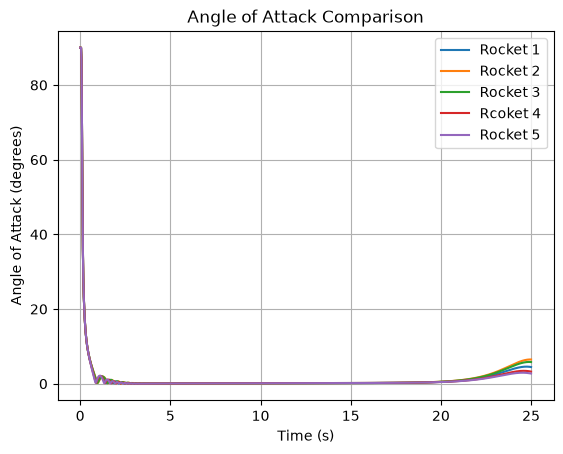

In [38]:
time = np.linspace(0,25,1000)


plt.figure()  
plt.plot(time,Flight1.angle_of_attack(time),label="Rocket 1")
plt.plot(time,Flight2.angle_of_attack(time),label="Rocket 2")
plt.plot(time,Flight3.angle_of_attack(time),label="Rocket 3")
plt.plot(time,Flight4.angle_of_attack(time),label="Rcoket 4")
plt.plot(time,Flight5.angle_of_attack(time),label="Rocket 5")

plt.xlabel("Time (s)")
plt.ylabel("Angle of Attack (degrees)")
plt.title("Angle of Attack Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 

## Angular Velocities Comparison

### Pitch Angular velocity:

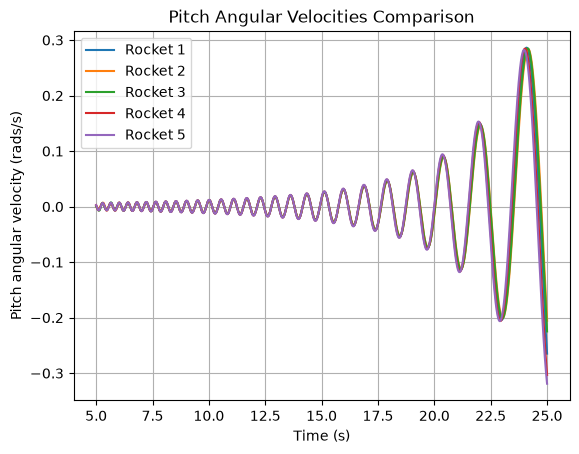

In [39]:
plt.figure()
w1_time = np.linspace(5,25,1000)
plt.plot(w1_time,Flight1.w1(w1_time),label="Rocket 1")
plt.plot(w1_time,Flight2.w1(w1_time),label="Rocket 2")
plt.plot(w1_time,Flight3.w1(w1_time),label="Rocket 3")
plt.plot(w1_time,Flight4.w1(w1_time),label="Rocket 4")
plt.plot(w1_time,Flight5.w1(w1_time),label="Rocket 5")

plt.xlabel("Time (s)")
plt.ylabel("Pitch angular velocity (rads/s)")
plt.title("Pitch Angular Velocities Comparison")
plt.legend()
plt.grid(True)
plt.show()


# Frequency Comparison

## Pitch frequency : 

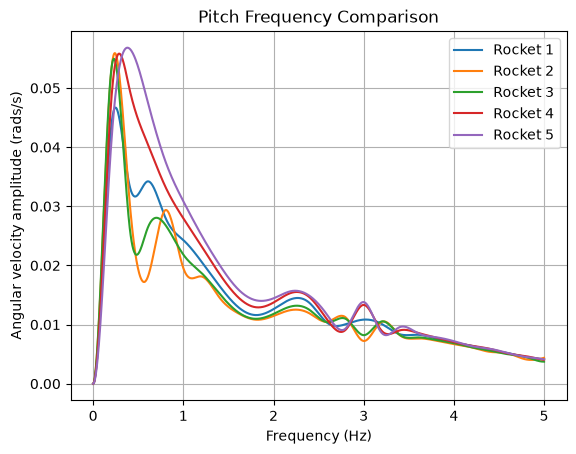

In [40]:
plt.figure()
omega1_frequency = np.linspace(0,5,1000)
plt.plot(omega1_frequency,Flight1.omega1_frequency_response(omega1_frequency),label="Rocket 1")
plt.plot(omega1_frequency,Flight2.omega1_frequency_response(omega1_frequency),label="Rocket 2")
plt.plot(omega1_frequency,Flight3.omega1_frequency_response(omega1_frequency),label="Rocket 3")
plt.plot(omega1_frequency,Flight4.omega1_frequency_response(omega1_frequency),label="Rocket 4")
plt.plot(omega1_frequency,Flight5.omega1_frequency_response(omega1_frequency),label="Rocket 5")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Angular velocity amplitude (rads/s)")
plt.title("Pitch Frequency Comparison")
plt.legend()
plt.grid(True)
plt.show()


# Stability Margin

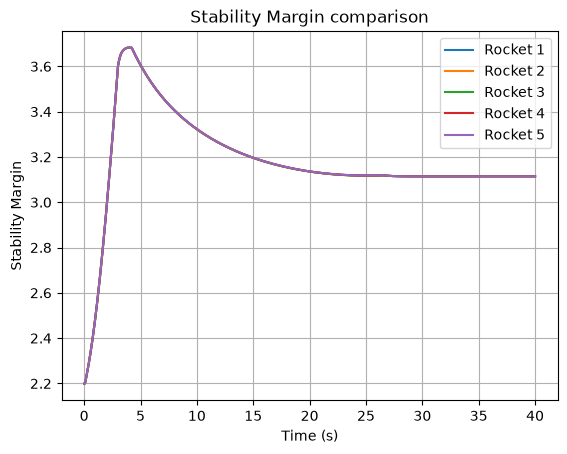

In [41]:
stability_time = np.linspace(0,40,1000)
plt.figure()
plt.plot(stability_time,Flight1.stability_margin(stability_time),label="Rocket 1")
plt.plot(stability_time,Flight2.stability_margin(stability_time),label="Rocket 2")
plt.plot(stability_time,Flight3.stability_margin(stability_time),label="Rocket 3")
plt.plot(stability_time,Flight4.stability_margin(stability_time),label="Rocket 4")
plt.plot(stability_time,Flight5.stability_margin(stability_time),label="Rocket 5")
plt.xlabel("Time (s)")
plt.ylabel("Stability Margin")
plt.title("Stability Margin comparison")
plt.legend()
plt.grid(True)
plt.show()

# Altidude Comparison

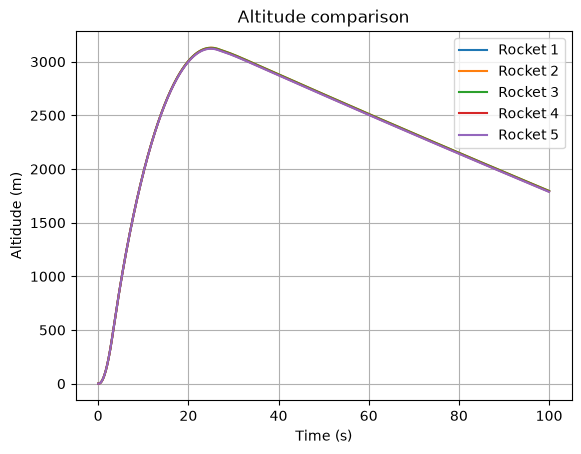

In [42]:
plt.figure()
altitude_time = np.linspace(0,100,1000)
plt.plot(altitude_time,Flight1.altitude(altitude_time),label="Rocket 1")
plt.plot(altitude_time,Flight2.altitude(altitude_time),label="Rocket 2")
plt.plot(altitude_time,Flight3.altitude(altitude_time),label="Rocket 3")
plt.plot(altitude_time,Flight4.altitude(altitude_time),label="Rocket 4")
plt.plot(altitude_time,Flight5.altitude(altitude_time),label="Rocket 5")
plt.xlabel("Time (s)")
plt.ylabel("Altidude (m)")
plt.title("Altitude comparison")
plt.legend()
plt.grid(True)
plt.show()